# Visibility Analysis with GRASS: Fire Lookout Towers

Rajveer Bishnoi  
2026-07-05

# Introduction

For much of the twentieth century, wildfires in the United States were
spotted by people. Lookouts climbed towers on high summits and scanned
the horizon for smoke, because the earlier a fire is spotted, the easier
it is to contain. Siting those towers was a visibility problem: where
should a tower go so it can see as much of the forest as possible?

We can reconstruct that reasoning with GRASS. A viewshed is the area of
terrain visible from an observation point, computed by
[r.viewshed](https://grass.osgeo.org/grass-stable/manuals/r.viewshed.html)
by tracing lines of sight across a digital elevation model. Our study
area is the Nantahala National Forest in western North Carolina, where
three historic lookout towers still stand along the Appalachian Trail
near the town of Franklin: Wayah Bald, Wesser Bald, and Albert Mountain.
Using them, we will answer four questions:

1.  Why put the lookout on a tower instead of standing on the summit?
2.  Does the curvature of the Earth matter at these distances?
3.  How does a rising smoke column change what a tower can detect?
4.  How much of the forest does the three-tower network cover, and where
    should a fourth tower go?

<figure>
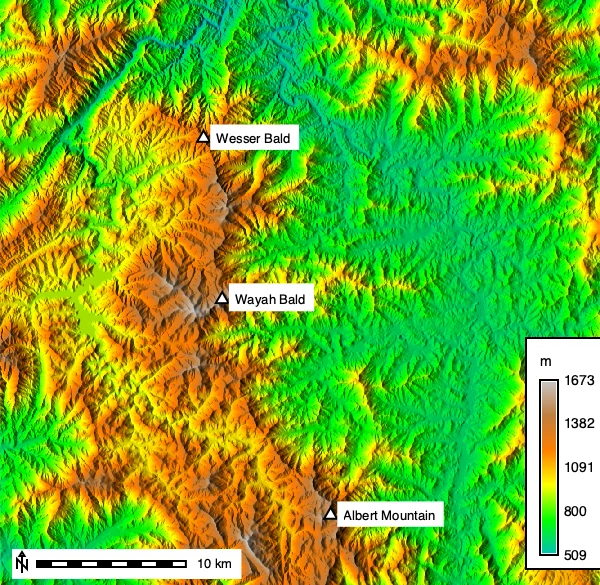
<figcaption aria-hidden="true">The fire towers of the Nantahala National
Forest on the terrain they were built to watch.</figcaption>
</figure>

> **How to run this tutorial**
>
> The code uses the GRASS Python API in a Jupyter notebook. If you are
> new to running GRASS from Python, see the [Get started with GRASS &
> Python](https://grass-tutorials.osgeo.org/content/tutorials/get_started/fast_track_grass_and_python.html)
> tutorial. Every step also works from the GRASS GUI or command line;
> use the tool name (for example `r.viewshed`) with the same parameters.

# Getting the elevation data

The towers are real places, so rather than use a prepackaged sample
dataset we download the terrain around them from the USGS. We create a
new GRASS project in UTM zone 17N (EPSG:32617) with
[create_project](https://grass.osgeo.org/grass-stable/manuals/libpython/script.html#script.core.create_project),
then fetch 1 arc-second (about 30 m) elevation from the USGS National
Map with
[r.in.usgs](https://grass.osgeo.org/grass-stable/manuals/addons/r.in.usgs.html),
an add-on installed with
[g.extension](https://grass.osgeo.org/grass-stable/manuals/g.extension.html).

In [1]:
import sys
import subprocess
from pathlib import Path

sys.path.append(
    subprocess.check_output(["grass", "--config", "python_path"], text=True).strip()
)

import grass.script as gs
import grass.jupyter as gj
from grass.tools import Tools

# Create the project once, then start a session in it
project = Path.home() / "nantahala"
if not project.exists():
    gs.create_project(project, epsg="32617")

session = gj.init(project)
tools = Tools()

tools.g_extension(extension="r.in.usgs")   # install the add-on (only needed once)

In [2]:
# A ~40 x 39 km window over the Nantahala Mountains, at 30 m resolution
tools.g_region(n=3916000, s=3877000, w=252000, e=292000, res=30)

# Download and import the current National Elevation Dataset for this region
tools.r_in_usgs(product="ned", ned_dataset="ned1sec", output_name="elevation",
                memory=1000, nprocs=2)
tools.g_region(raster="elevation")

> **About the download**
>
> This downloads the current 1 arc-second NED tile for the area (about
> 58 MB) and takes a couple of minutes, so the cell is not instant. Add
> `flags="i"` first to preview the tiles and total size without
> downloading. USGS occasionally republishes its elevation data, so the
> exact areas reported below may shift a little over time.

> **GRASS version**
>
> The examples use the [grass.tools
> API](https://grass.osgeo.org/grass-stable/manuals/python_intro.html)
> (the `Tools` class), introduced in GRASS 8.5. On earlier versions you
> can run the same tools with `gs.run_command("r.viewshed", ...)`.

# The study area

Let’s place the three towers and look at the terrain they watch over. We
enter their coordinates (converted from the published latitude and
longitude to UTM 17N) with
[v.in.ascii](https://grass.osgeo.org/grass-stable/manuals/v.in.ascii.html),
reading them straight from a text buffer with `StringIO`. We also record
the height of each tower’s cab above the ground, then read the summit
elevation from the DEM with
[v.what.rast](https://grass.osgeo.org/grass-stable/manuals/v.what.rast.html).

In [3]:
import io

towers_csv = """266819,3896041,Wayah Bald,16
265577,3906808,Wesser Bald,9
274053,3881661,Albert Mountain,12"""

tools.v_in_ascii(
    input=io.StringIO(towers_csv), output="towers", separator="comma",
    columns="x double precision, y double precision, name varchar(20), tower_m integer",
    x=1, y=2,
)
tools.v_what_rast(map="towers", raster="elevation", column="base_elev")
print(tools.v_db_select(map="towers").text)

The summits stand well above the surrounding valleys, from about 1400 m
at Wesser Bald to 1630 m at Wayah Bald. We render a shaded-relief base
with
[r.relief](https://grass.osgeo.org/grass-stable/manuals/r.relief.html),
drape the elevation colors over it with
[r.shade](https://grass.osgeo.org/grass-stable/manuals/r.shade.html),
and add the towers. A small helper labels each tower with
[d.text](https://grass.osgeo.org/grass-stable/manuals/d.text.html) just
to the right of its position in the current region.

In [4]:
tools.r_relief(input="elevation", output="relief", zscale=1.5)
tools.r_colors(map="elevation", color="elevation")
tools.r_shade(shade="relief", color="elevation", output="shaded_elev", brighten=30)

def label_towers(m, only=None):
    """Write each tower's name on map m, offset to the right of its marker."""
    r = tools.g_region(flags="g").keyval
    w, e, s, n = float(r["w"]), float(r["e"]), float(r["s"]), float(r["n"])
    for rec in tools.v_db_select(map="towers", format="json")["records"]:
        if only and rec["name"] not in only:
            continue
        x_pct = (rec["x"] - w) / (e - w) * 100
        y_pct = (rec["y"] - s) / (n - s) * 100
        m.d_text(text=rec["name"], at=(x_pct + 2.2, y_pct - 0.9), color="black",
                 size=2.8, bgcolor="white")

study = gj.Map(width=600)
study.d_rast(map="shaded_elev")
study.d_vect(map="towers", icon="basic/triangle", size=12,
             fill_color="white", color="black", width=2)
label_towers(study)
study.d_legend(raster="elevation", at=(5, 35, 90, 93), flags="b", fontsize=14, title="m")
study.d_barscale(flags="n", at=(2, 6), bgcolor="white", fontsize=13)
study.show()

# Why build a tower? Observer height

A lookout standing on Wayah Bald sees a certain area; the same lookout
in the tower cab sees more, because height clears the nearest ridges.
The `observer_elevation` parameter sets the eye height above the ground,
and the `-b` flag returns a boolean map where 1 means visible. Historic
lookouts were expected to watch a radius of roughly 20 miles, so we cap
the search at `max_distance=32000` (32 km) and, at that range, apply
Earth-curvature correction with `-c` (see the note below).

In [5]:
WAYAH = (266819, 3896041)

# A person standing on the summit (eye height 1.75 m)
tools.r_viewshed(input="elevation", output="wayah_ground", coordinates=WAYAH,
                 observer_elevation=1.75, max_distance=32000, flags="cb", memory=2000)

# The same lookout in the 16 m tower cab
tools.r_viewshed(input="elevation", output="wayah_tower", coordinates=WAYAH,
                 observer_elevation=16, max_distance=32000, flags="cb", memory=2000)

[r.report](https://grass.osgeo.org/grass-stable/manuals/r.report.html)
gives the area of each class in a viewshed. Category 1 is the visible
area; here it grows from about 165 km² at ground level to 277 km² from
the tower.

In [6]:
print(tools.r_report(map="wayah_ground", units="k", flags="n").text)
print(tools.r_report(map="wayah_tower", units="k", flags="n").text)

That is nearly 70% more visible area for 16 m of extra height, which is
what made the towers worth building. We draw the ground-level viewshed
in dark red and the extra area the tower adds in orange, zooming in
around Wayah Bald.

In [7]:
tools.r_mapcalc(expression="ground_vis = if(wayah_ground == 1, 1, null())")
tools.r_mapcalc(expression="tower_gain = if(wayah_tower == 1 && wayah_ground == 0, 1, null())")
tools.r_colors(map="ground_vis", rules=io.StringIO("1 178:24:43"))
tools.r_colors(map="tower_gain", rules=io.StringIO("1 239:138:98"))

# Save a closer view around Wayah Bald for this and the next map
tools.g_region(n=3908000, s=3884000, w=252000, e=284000, res=30, save="wayah_zoom")
tools.g_region(raster="elevation")   # keep the full region for analysis

height_map = gj.Map(width=600, saved_region="wayah_zoom")
height_map.d_rast(map="relief")
height_map.d_rast(map="tower_gain")
height_map.d_rast(map="ground_vis")
height_map.d_vect(map="towers", where="name='Wayah Bald'", icon="basic/triangle",
                  size=12, fill_color="white", color="black", width=2)
label_towers(height_map, only=["Wayah Bald"])
height_map.d_barscale(flags="n", at=(2, 6), bgcolor="white", fontsize=13)
height_map.show()

<figure>
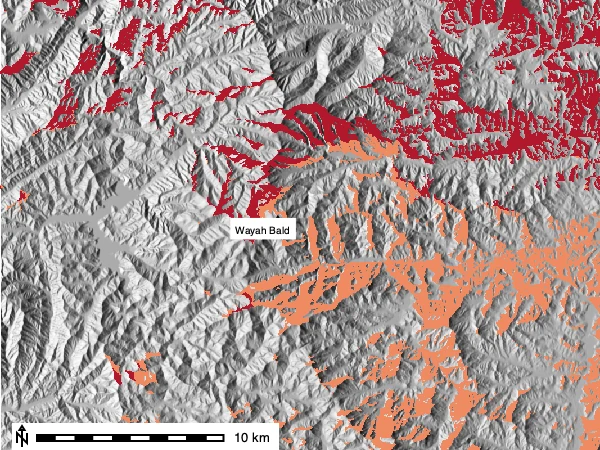
<figcaption aria-hidden="true">From Wayah Bald: visible standing on the
summit (dark red) and the extra area gained from the 16 m tower
(orange).</figcaption>
</figure>

> **Does Earth curvature matter here?**
>
> Over tens of kilometers, the curve of the Earth drops distant terrain
> below the line of sight. `r.viewshed` corrects for this with the `-c`
> flag. Rerunning the tower viewshed without `-c` reports about 282 km²
> instead of 277 km², an overestimate of roughly 2%. The effect is small
> here because visibility in these steep mountains is limited by
> intervening ridges rather than by the horizon; over flat land or water
> at the same range the correction matters much more. Atmospheric
> refraction, which bends light back down slightly, is a separate effect
> enabled by the `-r` flag with `refraction_coeff`; we leave it off.

# Seeing smoke, not ground

A lookout watches for smoke rising above the canopy, not for the forest
floor. A column of smoke a few meters tall can clear a ridge that hides
the ground behind it. `r.viewshed` models this with `target_elevation`,
the height of the target above the ground. We set it to 15 m, a modest
smoke column.

In [8]:
tools.r_viewshed(input="elevation", output="wayah_smoke", coordinates=WAYAH,
                 observer_elevation=16, target_elevation=15, max_distance=32000,
                 flags="cb", memory=2000)

print(tools.r_report(map="wayah_smoke", units="k", flags="n").text)

Allowing for a 15 m smoke column raises the detectable area from 277 km²
to about 412 km², nearly 50% more. In the map below the dark red is the
tower’s full terrain view (the 277 km² baseline) and orange is the extra
area where the ground is hidden but a 15 m smoke column would still be
visible.

In [9]:
tools.r_mapcalc(expression="terrain_vis = if(wayah_tower == 1, 1, null())")
tools.r_mapcalc(expression="smoke_gain = if(wayah_smoke == 1 && wayah_tower == 0, 1, null())")
tools.r_colors(map="terrain_vis", rules=io.StringIO("1 178:24:43"))
tools.r_colors(map="smoke_gain", rules=io.StringIO("1 253:184:99"))

smoke_map = gj.Map(width=600, saved_region="wayah_zoom")
smoke_map.d_rast(map="relief")
smoke_map.d_rast(map="smoke_gain")
smoke_map.d_rast(map="terrain_vis")
smoke_map.d_vect(map="towers", where="name='Wayah Bald'", icon="basic/triangle",
                 size=12, fill_color="white", color="black", width=2)
label_towers(smoke_map, only=["Wayah Bald"])
smoke_map.d_barscale(flags="n", at=(2, 6), bgcolor="white", fontsize=13)
smoke_map.show()

<figure>
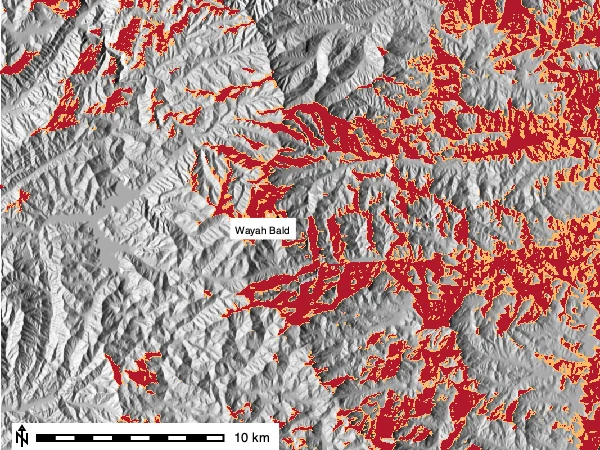
<figcaption aria-hidden="true">Wayah Bald tower: terrain visible (dark
red) and the extra area where a 15 m smoke column is detectable
(orange).</figcaption>
</figure>

# The tower network

One tower leaves gaps. Towers with overlapping views fill in each
other’s blind spots. We loop over the three towers, compute a
smoke-detection viewshed for each using its own cab height, and add the
boolean maps with
[r.series](https://grass.osgeo.org/grass-stable/manuals/r.series.html).
The sum tells us how many towers can detect a fire at each cell.

In [10]:
towers = tools.v_db_select(map="towers", format="json")["records"]

detection_maps = []
for t in towers:
    name = t["name"].split()[0].lower()   # wayah, wesser, albert
    out = f"detect_{name}"
    tools.r_viewshed(input="elevation", output=out, coordinates=(t["x"], t["y"]),
                     observer_elevation=t["tower_m"], target_elevation=15,
                     max_distance=32000, flags="cb", memory=2000)
    detection_maps.append(out)

# r.series sums to a floating-point map; make it integer so the classes are 1, 2, 3
tools.r_series(input=detection_maps, output="coverage_sum", method="sum")
tools.r_mapcalc(expression="coverage = int(coverage_sum)")
tools.r_null(map="coverage", setnull=0)   # drop cells that are not seen by any tower

How much of the forest does the network cover?
[r.report](https://grass.osgeo.org/grass-stable/manuals/r.report.html)
returns per-class areas, and its JSON output turns into a tidy table
with pandas.

In [11]:
import pandas as pd

report = tools.r_report(map="coverage", units=["k", "p"], format="json")
rows = []
for cat in report["categories"]:
    if cat["category"] not in (1, 2, 3):   # skip any no-data class
        continue
    area = next(u["value"] for u in cat["units"] if "kilo" in u["unit"])
    pct = next(u["value"] for u in cat["units"] if u["unit"] == "percent")
    rows.append({"seen by (towers)": cat["category"],
                 "area (km²)": round(area, 1), "share of region": f"{pct:.1f}%"})
pd.DataFrame(rows)

| seen by (towers) | area (km²) | share of region |
|------------------|------------|-----------------|
| 1                | 416.4      | 26.7%           |
| 2                | 214.8      | 13.7%           |
| 3                | 61.1       | 3.9%            |

The three towers together watch about 692 km², or 44% of this 1,562 km²
region. Only 4% is covered by all three at once, along the central
ridges where their circles overlap. We map the coverage with one color
per level.

In [12]:
tools.r_colors(map="coverage", rules=io.StringIO("1 254:224:139\n2 252:141:89\n3 213:62:79"))

coverage_map = gj.Map(width=600)
coverage_map.d_rast(map="relief")
coverage_map.d_rast(map="coverage")
coverage_map.d_vect(map="towers", icon="basic/triangle", size=12,
                    fill_color="white", color="black", width=2)
label_towers(coverage_map)
coverage_map.d_legend(raster="coverage", at=(5, 20, 90, 93), flags="b",
                      use=[1, 2, 3], fontsize=14, title="towers")
coverage_map.d_barscale(flags="n", at=(2, 6), bgcolor="white", fontsize=13)
coverage_map.show()

<figure>
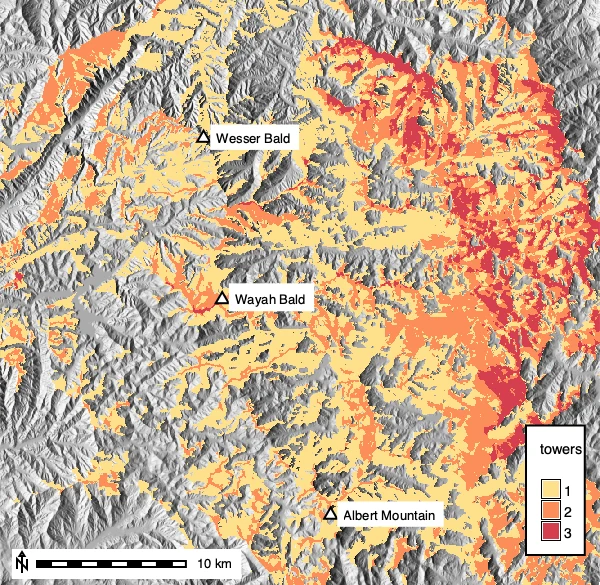
<figcaption aria-hidden="true">Network detection coverage: terrain seen
by one tower (yellow), two (orange), or all three (red).</figcaption>
</figure>

# Where should a fourth tower go?

The gap map turns “where should a new tower go?” into a computation. A
natural candidate is the highest summit that no current tower can see,
since high ground has the best chance of a long view. We isolate the
blind area, find its highest cell with
[r.stats](https://grass.osgeo.org/grass-stable/manuals/r.stats.html),
and test a tower there.

In [13]:
# cells no tower currently see, and their elevation
tools.r_mapcalc(expression="blind = if(isnull(coverage), 1, null())")
tools.r_mapcalc(expression="blind_elev = if(isnull(coverage), elevation, null())")

# coordinates of the highest blind cell
cells = tools.r_stats(input="blind_elev", flags="gn", format="json").json
peak = max(cells, key=lambda c: c["categories"][0]["category"])
cx, cy, cz = peak["east"], peak["north"], peak["categories"][0]["category"]
print(f"highest blind summit: ({cx:.0f}, {cy:.0f}), {cz:.0f} m")

# what a 12 m tower there would detect, and how much of the blind area it recovers
tools.r_viewshed(input="elevation", output="detect_new", coordinates=(cx, cy),
                 observer_elevation=12, target_elevation=15, max_distance=32000,
                 flags="cb", memory=2000)
tools.r_mapcalc(expression="recovered = if(isnull(coverage) && detect_new == 1, 1, null())")

print(tools.r_report(map="blind", units="k", flags="n").text)
print(tools.r_report(map="recovered", units="k", flags="n").text)

The best-placed new tower recovers only about 28 km² of the 870 km²
blind area, less than 4% of it. The gap map shows why: what remains
unseen is mostly the valley bottoms between the ridges, and no ridgetop
tower can see down into a ravine. Beyond a handful of well-sited towers,
adding more brings sharply diminishing returns. Fire agencies eventually
turned to aircraft patrols and, later, camera and satellite detection
for exactly this reason.

In [14]:
tools.r_mapcalc(expression="covered_now = if(!isnull(coverage), 1, null())")
tools.r_colors(map="covered_now", rules=io.StringIO("1 150:180:200"))
tools.r_colors(map="recovered", rules=io.StringIO("1 215:25:28"))
tools.v_in_ascii(input=io.StringIO(f"{cx:.0f},{cy:.0f}"), output="candidate",
                 separator="comma", columns="x double precision, y double precision",
                 x=1, y=2)

site_map = gj.Map(width=600)
site_map.d_rast(map="relief")
site_map.d_rast(map="covered_now")
site_map.d_rast(map="recovered")
site_map.d_vect(map="towers", icon="basic/triangle", size=12,
                fill_color="white", color="black", width=2)
site_map.d_vect(map="candidate", icon="basic/star", size=18,
                fill_color="yellow", color="black", width=2)
site_map.d_barscale(flags="n", at=(2, 6), bgcolor="white", fontsize=13)
site_map.show()

<figure>
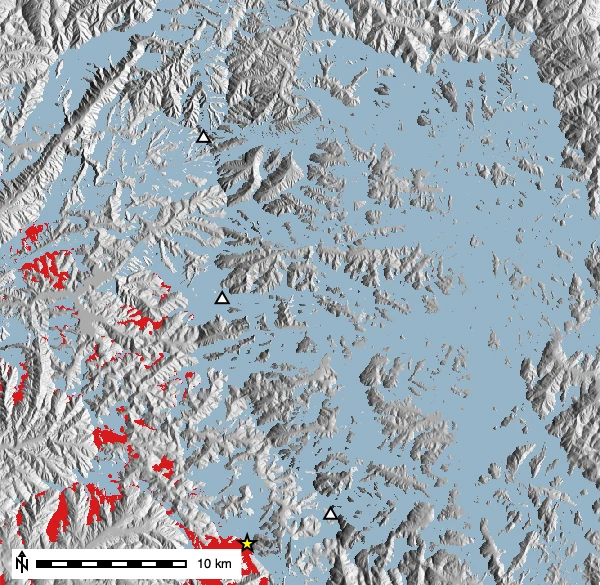
<figcaption aria-hidden="true">Existing coverage (blue), the candidate
fourth tower (star), and the small area it recovers (red). Most gaps are
valleys no ridgetop tower can see.</figcaption>
</figure>

# Summary

We have used
[r.viewshed](https://grass.osgeo.org/grass-stable/manuals/r.viewshed.html)
on USGS elevation data to answer the four questions from the
introduction:

- A 16 m tower sees nearly 70% more terrain than a person standing on
  the same summit (`observer_elevation`).
- Earth curvature (`-c`) is a small correction in this rugged terrain,
  where ridges rather than the horizon limit the view.
- A rising smoke column (`target_elevation`) can be detected over far
  more ground than is directly visible.
- Three towers cover 44% of the forest, and the gaps that remain are
  valleys where even a well-placed fourth tower gains little.

To combine visibility with routes across the terrain, see [Modeling
Movement in GRASS](../modeling_movement/GRASS_movement.qmd).